# Keras ile Basit Sinir Ağı Modeli Kurma
Bu örnekte, Keras kullanarak basit bir yapay sinir ağı modeli oluşturacağız. Veri olarak klasik XOR problemini kullanacağız.
Model sıfırdan oluşturulacak, eğitilecek ve sonuçlar incelenecektir.

In [1]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import tensorflow as tf

# TensorFlow versiyon kontrolü
print("TensorFlow sürümü:", tf.__version__)


TensorFlow sürümü: 2.18.0


## Veri Seti
XOR problemini çözecek veri setini tanımlıyoruz:

In [2]:
# Girdi verileri
X = np.array([[0, 0],
              [0, 1],
              [1, 0],
              [1, 1]])

# Çıkış verileri (etiketler)
y = np.array([0, 1, 1, 0])


## Modelin Oluşturulması
Model 1 gizli katman ve 1 çıkış katmanından oluşur.

In [22]:
# Model tanımı
model = Sequential()

# Gizli katman (4 nöron, ReLU aktivasyon)
model.add(Dense(18, input_shape=(2,), activation='relu'))

# Çıkış katmanı (1 nöron, sigmoid aktivasyon)
model.add(Dense(1, activation='sigmoid'))

# Model özeti
model.summary()


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                │ (None, 18)             │            54 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            19 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 73 (292.00 B)

 Trainable params: 73 (292.00 B)

 Non-trainable params: 0 (0.00 B)

## Modelin Derlenmesi
Kayıp fonksiyonu, optimizasyon algoritması ve başarı metriği tanımlanır.

In [24]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])


## Modelin Eğitimi
Model 100 epoch boyunca eğitilecektir.

In [25]:
history = model.fit(X, y, epochs=100, verbose=0)
print("Eğitim tamamlandı.")


Eğitim tamamlandı.


## Eğitim Doğruluğu ve Kayıp Grafiği

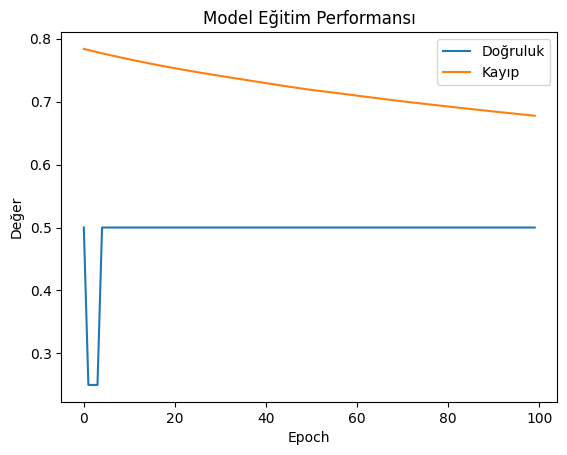

In [26]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Doğruluk')
plt.plot(history.history['loss'], label='Kayıp')
plt.xlabel("Epoch")
plt.ylabel("Değer")
plt.legend()
plt.title("Model Eğitim Performansı")
plt.show()


## Tahminler
Modelin XOR çıktısını doğru öğrenip öğrenmediği kontrol edilir.

In [27]:
# Tahminler
tahminler = model.predict(X)
print("Ham Tahminler:")
print(tahminler)

# Yuvarlanmış çıktılar
print("Yuvarlanmış Tahminler:")
print(np.round(tahminler))


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
Ham Tahminler:
[[0.5171563 ]
 [0.5610986 ]
 [0.46126923]
 [0.4660929 ]]
Yuvarlanmış Tahminler:
[[1.]
 [1.]
 [0.]
 [0.]]
